# Praktikum 1 - Regresi Linier (Simple, Multiple, Polynomial & OLS Statsmodels)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Bagian A: Studi Kasus Teori Dasar (Prediksi Harga Pizza)

Sebelum masuk ke dataset utama pada Praktikum 1, saya mencoba terlebih dahulu tiga model dasar yang dibahas pada bagian teori modul, yaitu **Simple Linear Regression** (beserta evaluasi *Cost Function* RSS, TSS, $R^2$, MAE, dan MSE), **Multiple Linear Regression**, serta **Polynomial Regression** pada studi kasus hubungan diameter dan jumlah *topping* pizza terhadap harganya.

### 1. Simple Linear Regression & Evaluasi Cost Function (RSS, TSS, $R^2$, MAE, MSE)

Predicted Price in Dollar: [ 7.664  9.612 11.56  15.456 19.352]
Residual Sum of Squares (RSS): 8.89488
Total Sum of Squares (TSS): 97.19999999999999
R-squared (R2): 0.9084888888888889
MAE (Mean Absolute Error): 1.2224
MSE (Mean Squared Error): 1.7789760000000001


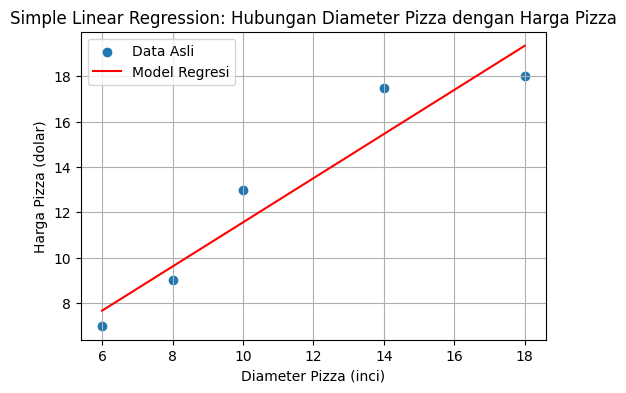

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Data diameter pizza (inci) dan harga pizza (dolar)
diameter_pizza = np.array([6, 8, 10, 14, 18])
harga_pizza_asli = np.array([7, 9, 13, 17.5, 18])

# Estimasi parameter regresi linier sederhana
beta_0 = 1.82
beta_1 = 0.974

# Model regresi
harga_pizza_prediksi = beta_0 + beta_1 * diameter_pizza

# Menghitung RSS, TSS, R2, MAE, dan MSE
RSS = np.sum((harga_pizza_asli - harga_pizza_prediksi) ** 2)
TSS = np.sum((harga_pizza_asli - np.mean(harga_pizza_asli)) ** 2)
R2 = 1 - (RSS / TSS)
mae = mean_absolute_error(harga_pizza_asli, harga_pizza_prediksi)
mse = mean_squared_error(harga_pizza_asli, harga_pizza_prediksi)

print("Predicted Price in Dollar:", harga_pizza_prediksi)
print("Residual Sum of Squares (RSS):", RSS)
print("Total Sum of Squares (TSS):", TSS)
print("R-squared (R2):", R2)
print("MAE (Mean Absolute Error):", mae)
print("MSE (Mean Squared Error):", mse)

# Visualisasi Simple Linear Regression
plt.figure(figsize=(6, 4))
plt.scatter(diameter_pizza, harga_pizza_asli, label='Data Asli')
plt.plot(diameter_pizza, harga_pizza_prediksi, color='red', label='Model Regresi')
plt.xlabel('Diameter Pizza (inci)')
plt.ylabel('Harga Pizza (dolar)')
plt.title('Simple Linear Regression: Hubungan Diameter Pizza dengan Harga Pizza')
plt.legend()
plt.grid(True)
plt.show()

### 2. Multiple Linear Regression & Polynomial Regression (Degree = 2)

Selanjutnya saya membandingkan model **Multiple Linear Regression** dan **Polynomial Regression** (`degree = 2`) ketika ditambahkan variabel bebas kedua yaitu jumlah *topping* pizza.

=== Hasil Prediksi Harga Pizza (Multiple Linear Regression) ===
Data Test 1: Prediksi $9.00, Target $11.00
Data Test 2: Prediksi $11.97, Target $8.50
Data Test 3: Prediksi $12.31, Target $15.00
Data Test 4: Prediksi $17.81, Target $18.00
Data Test 5: Prediksi $15.27, Target $11.00
R-squared (R2) Multiple Linear: 0.27

R-squared (R2) Polynomial (degree=2): 0.34


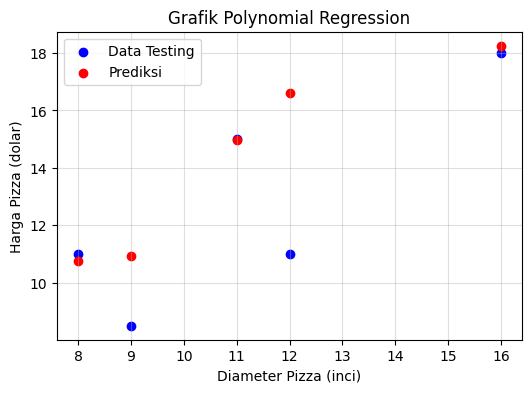

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# Data training (Diameter Pizza, Jumlah Topping)
X_train_pz = np.array([
    [6, 2],
    [8, 1],
    [10, 0],
    [14, 2],
    [18, 3]
])
y_train_pz = np.array([7, 9, 13, 17.5, 18])

# Data testing
X_test_pz = np.array([
    [8, 2],
    [9, 0],
    [11, 2],
    [16, 2],
    [12, 0]
])
y_test_pz = np.array([11, 8.5, 15, 18, 11])

# 1. Multiple Linear Regression
model_mlr = LinearRegression()
model_mlr.fit(X_train_pz, y_train_pz)
y_pred_mlr = model_mlr.predict(X_test_pz)
r2_mlr = r2_score(y_test_pz, y_pred_mlr)

print("=== Hasil Prediksi Harga Pizza (Multiple Linear Regression) ===")
for i in range(len(y_pred_mlr)):
    print(f"Data Test {i + 1}: Prediksi ${y_pred_mlr[i]:.2f}, Target ${y_test_pz[i]:.2f}")
print(f"R-squared (R2) Multiple Linear: {r2_mlr:.2f}\n")

# 2. Polynomial Regression (degree=2)
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_pz)
X_test_poly = poly.transform(X_test_pz)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train_pz)
y_pred_poly = model_poly.predict(X_test_poly)
r2_poly = r2_score(y_test_pz, y_pred_poly)

print(f"R-squared (R2) Polynomial (degree=2): {r2_poly:.2f}")

plt.figure(figsize=(6, 4))
plt.scatter(X_test_pz[:, 0], y_test_pz, color='blue', label='Data Testing')
plt.scatter(X_test_pz[:, 0], y_pred_poly, color='red', label='Prediksi')
plt.title('Grafik Polynomial Regression')
plt.xlabel('Diameter Pizza (inci)')
plt.ylabel('Harga Pizza (dolar)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Dari percobaan awal di atas, terlihat bahwa dengan hanya satu fitur (`Diameter Pizza`), garis regresi linier sederhana memiliki kecocokan yang sangat tinggi pada data *training* ($R^2 = 0.9085$, $\text{RSS} = 8.8949$). Ketika diuji pada data *testing* dua fitur (`Diameter Pizza` dan `Jumlah Topping`), model **Multiple Linear Regression** menghasilkan $R^2 = 0.27$, sedangkan ekspansi fitur ke **Polynomial Regression** derajat 2 berhasil meningkatkan kemampuan model menangkap kelengkungan hubungan data sehingga nilai $R^2$ pada data uji naik menjadi `0.34`.

---

## Bagian B: Praktikum 1 - Regresi Linier pada `dataset.csv`

### Langkah 1, 2, & 3: Persiapan Data, Import Library, dan Baca Data

Memuat pustaka `numpy` dan `pandas`, kemudian membaca file `dataset.csv` yang berisi data pelanggan *e-commerce*.

In [3]:
# import package
import numpy as np
import pandas as pd

# baca data dari file CSV
data = pd.read_csv('dataset.csv')
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


### Langkah 4: Pemahaman Terhadap Data

Mengecek dimensi ukuran dataset (`data.shape`), tipe kolom dan kelengkapan data (`data.info()`), serta statistik deskriptif (`data.describe()`).

In [4]:
# mengecek ukuran data
print("Ukuran data (baris, kolom):", data.shape)

# informasi tentang data
data.info()

# deskripsi statistik data
data.describe()

Ukuran data (baris, kolom): (500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


Berdasarkan output di atas, `dataset.csv` terdiri dari `500` baris dan `8` kolom tanpa adanya nilai yang hilang (*500 non-null*). Terdapat 3 kolom bertipe teks (`Email`, `Address`, `Avatar`) dan 5 kolom bertipe numerik `float64`, yaitu `Avg. Session Length` (rata-rata `33.05` menit), `Time on App` (rata-rata `12.05` menit), `Time on Website` (rata-rata `37.06` menit), `Length of Membership` (rata-rata `3.53` tahun), serta variabel target `Yearly Amount Spent` (rata-rata pengeluaran tahunan sebesar `$499.31` dengan simpangan baku `$79.31`).

### Langkah 5: Visualisasi Data

Menggunakan `seaborn.pairplot` untuk melihat sebaran hubungan antara kandidat variabel bebas (`Time on App`, `Time on Website`, `Length of Membership`) terhadap `Yearly Amount Spent`, dilanjutkan dengan `seaborn.heatmap` untuk menghitung koefisien korelasi Pearson antar fitur numerik.

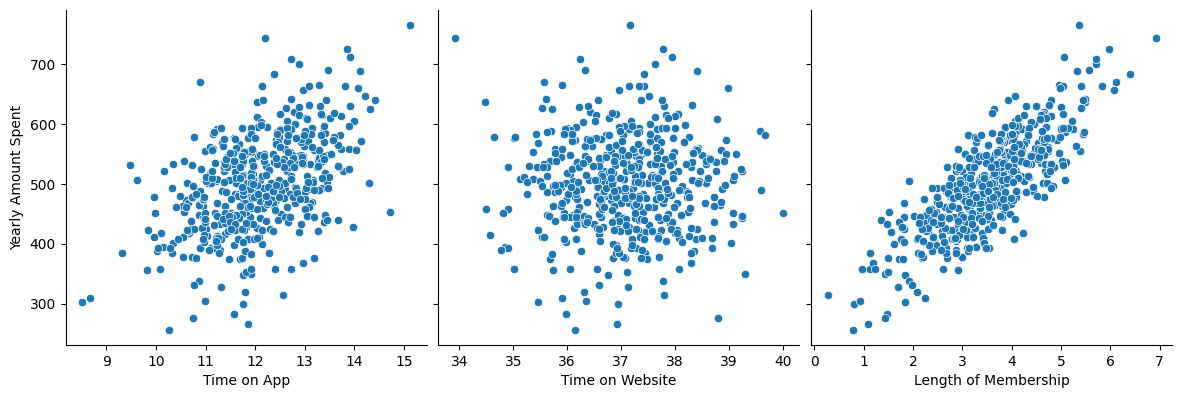

In [5]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

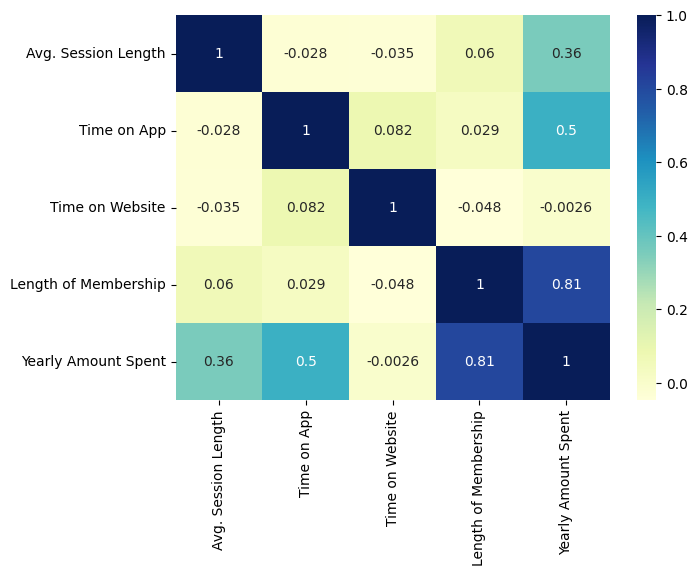

In [6]:
# visualisasi korelasi dengan heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

Dari visualisasi *pairplot* dan *heatmap* korelasi di atas, terlihat sangat jelas bahwa variabel `Length of Membership` memiliki korelasi linier positif paling kuat terhadap `Yearly Amount Spent` dengan nilai koefisien korelasi sebesar `0.81` (`0.809084`), diikuti oleh `Time on App` (`0.50`) dan `Avg. Session Length` (`0.36`). Sebaliknya, `Time on Website` memiliki korelasi `-0.0026` (mendekati nol) sehingga hampir tidak memiliki hubungan linier terhadap total belanja tahunan pelanggan.

### Langkah 6: Regresi Linier Menggunakan `statsmodels.api.OLS`

Berdasarkan hasil analisis korelasi sebelumnya, variabel `Length of Membership` dipilih sebagai variabel bebas `X` untuk memprediksi `Yearly Amount Spent` (`y`). Data dibagi menjadi data latih (`70%` = 350 baris) dan data uji (`30%` = 150 baris) dengan `random_state = 100`, kemudian dilatih menggunakan metode *Ordinary Least Squares* (`sm.OLS`).

In [7]:
# Membuat variabel bebas X dan Y dari hasil analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

X.head()

0    4.082621
1    2.664034
2    4.104543
3    3.120179
4    4.446308
Name: Length of Membership, dtype: float64

In [8]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

print(f"Jumlah data latih: {len(X_train)}, Jumlah data uji: {len(X_test)}")
X_train.head()

Jumlah data latih: 350, Jumlah data uji: 150


153    6.076654
84     4.396652
310    3.363411
494    2.768852
126    4.106055
Name: Length of Membership, dtype: float64

In [9]:
# Training model menggunakan statsmodels
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
lr.params

const                   265.248299
Length of Membership     66.301522
dtype: float64

In [10]:
# Analisis statistika dari garis regresi
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         11:50:29   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

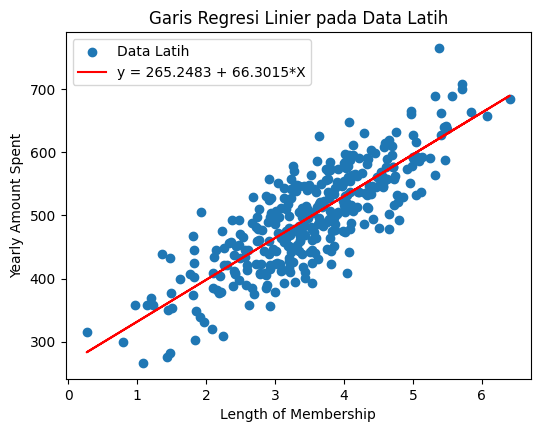

In [11]:
# Visualisasi garis regresi pada data latih
plt.figure(figsize=(6, 4.5))
plt.scatter(X_train, y_train, label='Data Latih')
plt.plot(X_train, 265.2483 + 66.3015 * X_train, 'r', label='y = 265.2483 + 66.3015*X')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title('Garis Regresi Linier pada Data Latih')
plt.legend()
plt.show()

Dari ringkasan `lr.summary()` pada 350 data latih, diperoleh persamaan garis regresi:

$$\text{Yearly Amount Spent} = 265.2483 + 66.3015 \times \text{Length of Membership}$$

Nilai *intercept* (`const`) sebesar `265.2483` dan koefisien kemiringan (`Length of Membership`) sebesar `66.3015` keduanya memiliki nilai $P > |t|$ sebesar `0.000` (sangat signifikan secara statistik). Artinya, setiap penambahan 1 tahun masa keanggotaan pelanggan rata-rata meningkatkan pengeluaran tahunan sebesar `$66.30`. Nilai `R-squared` pada data latih adalah `0.669` (`66.9%` variasi pengeluaran tahunan dapat dijelaskan oleh lama keanggotaan).

### Langkah 7: Analisis Residual

Menghitung *residual* (`res = y_train - y_train_pred`) pada data latih, lalu memvisualisasikannya dengan histogram distribusi error dan *scatter plot* terhadap `X_train` untuk memeriksa asumsi normalitas dan homoskedastisitas.

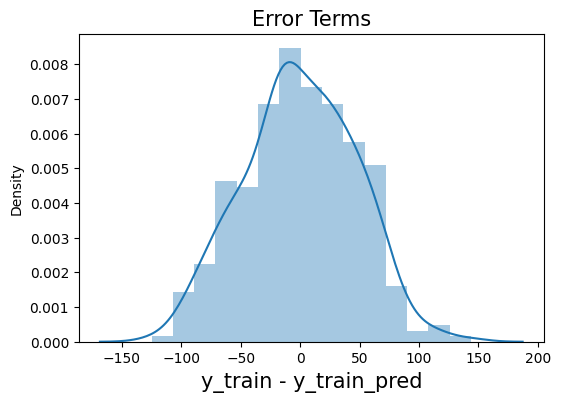

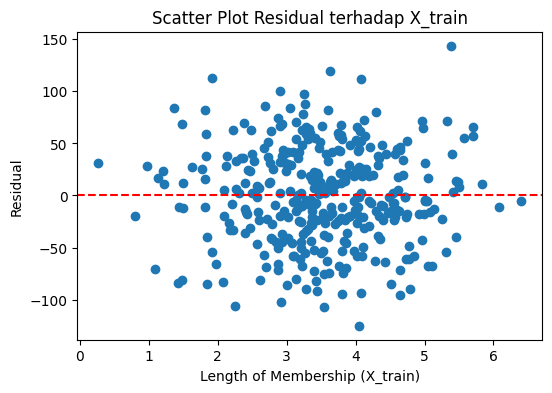

In [12]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

# Histogram residual
fig = plt.figure(figsize=(6, 4))
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.figure(figsize=(6, 4))
plt.scatter(X_train, res)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Length of Membership (X_train)')
plt.ylabel('Residual')
plt.title('Scatter Plot Residual terhadap X_train')
plt.show()

Pada grafik histogram *Error Terms* di atas, distribusi residual tampak berbentuk lonceng simetris yang berpusat di sekitar angka `0` (sesuai pula dengan nilai statistik `Skew = -0.013` dan `Prob(Omnibus) = 0.440 > 0.05` pada tabel OLS yang menandakan residual berdistribusi normal). Selain itu, pada *scatter plot* antara `X_train` dan `res`, titik-titik error menyebar secara acak merata di atas dan di bawah garis nol tanpa membentuk pola mengerucut ataupun melengkung, yang berarti asumsi homoskedastisitas (ragam galat konstan) terpenuhi.

### Langkah 8 & 9: Prediksi pada Data Uji, Evaluasi $R^2$, dan Visualisasi Hasil

Menambahkan konstanta pada `X_test`, melakukan prediksi `y_test_pred`, menghitung skor $R^2$ pada data uji, serta memvisualisasikan kecocokan garis regresi terhadap 150 titik data uji.

In [13]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Cetak 5 data terprediksi teratas
print("5 hasil prediksi teratas pada data uji:")
print(y_test_pred.head())

# Hitung nilai R-squared
from sklearn.metrics import r2_score
r_squared = r2_score(y_test, y_test_pred)
print(f"\nR-squared (R2) pada data uji: {r_squared:.4f}")

5 hasil prediksi teratas pada data uji:
69     500.794385
29     579.688406
471    533.188991
344    446.066436
54     455.838449
dtype: float64

R-squared (R2) pada data uji: 0.6119


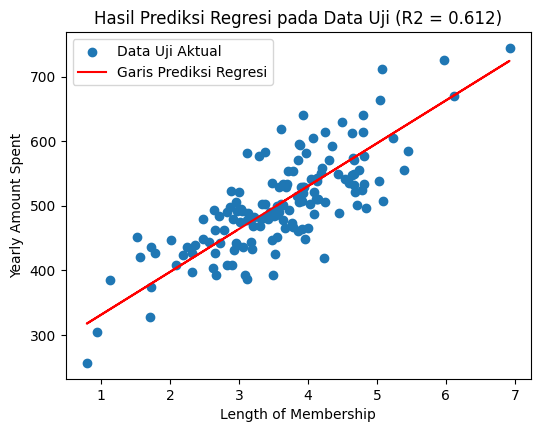

In [14]:
# Visualisasi data uji dan hasil prediksi
plt.figure(figsize=(6, 4.5))
plt.scatter(X_test, y_test, label='Data Uji Aktual')
plt.plot(X_test, y_test_pred, 'r', label='Garis Prediksi Regresi')
plt.xlabel('Length of Membership')
plt.ylabel('Yearly Amount Spent')
plt.title(f'Hasil Prediksi Regresi pada Data Uji (R2 = {r_squared:.3f})')
plt.legend()
plt.show()

### Kesimpulan Praktikum 1

Nilai $R^2$ pada data uji diperoleh sebesar `0.6119` (`61.2%`), yang nilainya cukup dekat dengan $R^2$ pada data latih yaitu `0.669` (`66.9%`). Selisih yang kecil antara performa *training* dan *testing* menunjukkan bahwa model regresi linier sederhana ini stabil dan tidak mengalami *overfitting*, serta membuktikan bahwa fitur `Length of Membership` sendiri sudah mampu menjelaskan lebih dari 61% variasi pengeluaran tahunan pelanggan pada data baru.